<a href="https://colab.research.google.com/github/Maranty/CardiaSense/blob/main/cardiasense_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [182]:
!pip install ucimlrepo

In [183]:
!pip install scikit-learn==1.7.2

In [184]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, TunedThresholdClassifierCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
import joblib
import shap
import matplotlib.pyplot as plt

In [185]:
df = fetch_ucirepo(id=45)

X = df.data.features
y = (df.data.targets["num"] != 0).astype(int)

In [186]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [187]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [188]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

In [189]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [190]:
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [191]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [192]:
pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42))
])

In [193]:
param_grid = [
    {"model__penalty": ["l2"], "model__C": [0.01, 0.1, 1, 10], "model__solver": ["lbfgs"]},
    {"model__penalty": ["l1"], "model__C": [0.01, 0.1, 1, 10], "model__solver": ["liblinear"]},
]

In [194]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [195]:
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=1)

In [196]:
lr_model = TunedThresholdClassifierCV(grid, cv=cv, scoring="f1", random_state=42, n_jobs=-1)

In [197]:
lr_model.fit(X_train, y_train)

,estimator,GridSearchCV(... scoring='f1')
,scoring,'f1'
,response_method,'auto'
,thresholds,100
,cv,StratifiedKFo... shuffle=True)
,refit,True
,n_jobs,-1
,random_state,42
,store_cv_results,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'


In [198]:
print("Threshold:", lr_model.best_threshold_)

Threshold: 0.4901313671928812


In [199]:
y_pred = lr_model.predict(X_test)

###Baseline Model Comparison:

In [200]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

,strategy,'most_frequent'
,random_state,None
,constant,None


In [201]:
baseline_pred = baseline.predict(X_test)

In [202]:
print("Baseline Prediction:\n", baseline_pred)
print("\nLogistic Regression Prediction:\n", y_pred)

Baseline Prediction:
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Logistic Regression Prediction:
 [0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 1 0
 0 0 1 1 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1]


In [203]:
test_comparison = pd.DataFrame([
    {
        "Model": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Recall": recall_score(y_test, baseline_pred, zero_division=0),
        "F1": f1_score(y_test, baseline_pred, zero_division=0),
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
    },
])

print(test_comparison.round(4).to_string(index=False))

              Model  Accuracy  Recall     F1
           Baseline    0.5410  0.0000 0.0000
Logistic Regression    0.8852  0.9643 0.8852


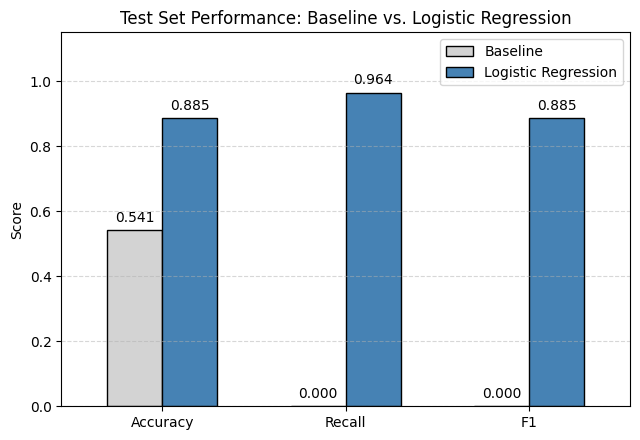

In [204]:
plot_df = test_comparison.set_index("Model")[["Accuracy", "Recall", "F1"]].T

ax = plot_df.plot.bar(
    color=["lightgray", "steelblue"],
    edgecolor="black",
    width=0.6,
    figsize=(6.5, 4.5),
    rot=0,
    title="Test Set Performance: Baseline vs. Logistic Regression",
)

for container in ax.containers:
  ax.bar_label(container, fmt="%.3f", padding=4, fontsize=10)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [205]:
scoring = ["accuracy", "recall", "f1"]

model_scores = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

comparison = []

for metric in scoring:
    baseline_values = baseline_scores[f"test_{metric}"]
    model_values = model_scores[f"test_{metric}"]

    comparison.append({
        "Metric": metric.capitalize(),
        "Baseline Mean": baseline_values.mean(),
        "Baseline Std": baseline_values.std(),
        "Logistic Regression Mean": model_values.mean(),
        "Logistic Regression Std": model_values.std()
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

  Metric  Baseline Mean  Baseline Std  Logistic Regression Mean  Logistic Regression Std
Accuracy         0.5413        0.0065                    0.8389                   0.0240
  Recall         0.0000        0.0000                    0.8008                   0.0750
      F1         0.0000        0.0000                    0.8197                   0.0252


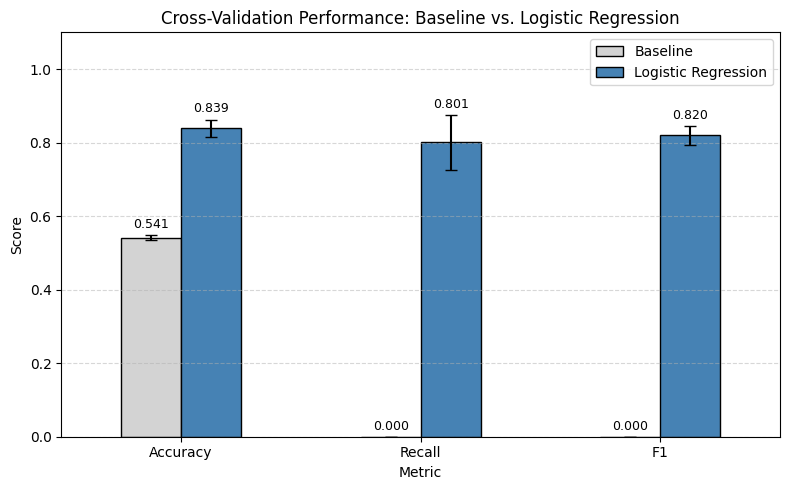

In [206]:
ax = comparison_df.plot.bar(
    x="Metric",
    y=["Baseline Mean", "Logistic Regression Mean"],
    yerr=comparison_df[["Baseline Std", "Logistic Regression Std"]].values.T,
    capsize=4,
    color=["lightgray", "steelblue"],
    edgecolor="black",
    figsize=(8, 5),
    rot=0,
    title="Cross-Validation Performance: Baseline vs. Logistic Regression",
)

for container in ax.containers:
  if hasattr(container, "patches"):
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.1)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(["Baseline", "Logistic Regression"], loc="upper right")

plt.tight_layout()
plt.show()

###Logistic Regression Coefficient Analysis:

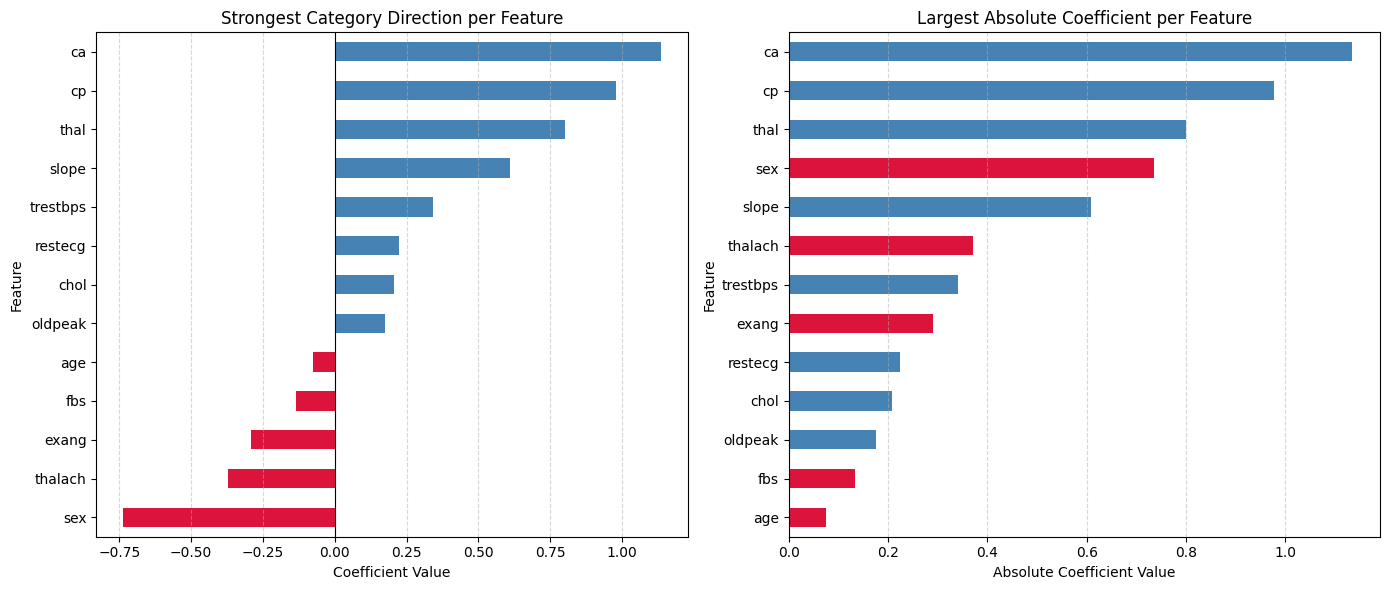

In [207]:
preprocessor_step = lr_model.estimator_.best_estimator_.named_steps["preprocessor"]
selected_features = preprocessor_step.get_feature_names_out()
coefficients = lr_model.estimator_.best_estimator_.named_steps["model"].coef_[0]

original_names = [
    feat.split("__")[-1].split("_")[0] for feat in selected_features
]

raw_df = pd.DataFrame({
    "Feature": original_names,
    "Coefficient": coefficients,
    "Absolute Coefficient": np.abs(coefficients),
})

idx_max = raw_df.groupby("Feature")["Absolute Coefficient"].idxmax()
feature_coefficient = raw_df.loc[idx_max].sort_values(
    by="Absolute Coefficient", ascending=False
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left Plot: Signed Coefficient of the strongest category per feature
plot_df1 = feature_coefficient.sort_values(by="Coefficient", ascending=True)
colors1 = ["crimson" if c < 0 else "steelblue" for c in plot_df1["Coefficient"]]

plot_df1.plot.barh(
    x="Feature",
    y="Coefficient",
    color=colors1,
    legend=False,
    ax=ax1,
    title="Strongest Category Direction per Feature",
)
ax1.axvline(0, color="black", linewidth=0.8)
ax1.grid(axis="x", linestyle="--", alpha=0.5)
ax1.set_xlabel("Coefficient Value")

# Right Plot: Overall Feature Importance (Magnitude)
plot_df2 = feature_coefficient.sort_values(
    by="Absolute Coefficient", ascending=True
)
colors2 = ["crimson" if c < 0 else "steelblue" for c in plot_df2["Coefficient"]]

plot_df2.plot.barh(
    x="Feature",
    y="Absolute Coefficient",
    color=colors2,
    legend=False,
    ax=ax2,
    title="Largest Absolute Coefficient per Feature",
)
ax2.grid(axis="x", linestyle="--", alpha=0.5)
ax2.set_xlabel("Absolute Coefficient Value")

plt.tight_layout()
plt.show()

In [208]:
print("\nThe Most Important Measurements: ")
feature_coefficient.head()


The Most Important Measurements: 


,Feature,Coefficient,Absolute Coefficient
5,ca,1.133645,1.133645
11,cp,0.977327,0.977327
24,thal,0.800566,0.800566
6,sex,-0.736163,0.736163
20,slope,0.608022,0.608022


###Make It Your Own: Routine Checkup Only

In [209]:
routine_num_cols = ["age", "trestbps", "chol"]
routine_cat_cols = ["sex", "cp", "fbs", "restecg"]
routine_features = routine_num_cols + routine_cat_cols

X_train_routine = X_train[routine_features]
X_test_routine = X_test[routine_features]

In [210]:
routine_preprocessor = ColumnTransformer([
    ("num", num_pipeline, routine_num_cols),
    ("cat", cat_pipeline, routine_cat_cols)
])

In [211]:
routine_pipe = Pipeline([
    ("preprocessor", routine_preprocessor),
    ("model", LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42))
])

In [212]:
routine_grid = GridSearchCV(routine_pipe, param_grid, cv=cv, scoring="f1", n_jobs=1)

In [213]:
routine_lr_model = TunedThresholdClassifierCV(routine_grid, cv=cv, scoring="f1", random_state=42, n_jobs=-1)
routine_lr_model.fit(X_train_routine, y_train)

,estimator,GridSearchCV(... scoring='f1')
,scoring,'f1'
,response_method,'auto'
,thresholds,100
,cv,StratifiedKFo... shuffle=True)
,refit,True
,n_jobs,-1
,random_state,42
,store_cv_results,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'


In [214]:
y_pred_routine = routine_lr_model.predict(X_test_routine)

In [215]:
print("Threshold:", routine_lr_model.best_threshold_)

Threshold: 0.5140112932014017


In [216]:
print("Full Model:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Disease", "Heart Disease"],
    zero_division=0
))

print("Routine Model:")
print(classification_report(
    y_test,
    y_pred_routine,
    target_names=["No Disease", "Heart Disease"],
    zero_division=0
))


full_auc = roc_auc_score(y_test, lr_model.predict_proba(X_test)[:, 1])
routine_auc = roc_auc_score(y_test, routine_lr_model.predict_proba(X_test_routine)[:, 1])

print(f"Full Model ROC-AUC:    {full_auc:.4f}")
print(f"Routine Model ROC-AUC: {routine_auc:.4f}")

Full Model:
               precision    recall  f1-score   support

   No Disease       0.96      0.82      0.89        33
Heart Disease       0.82      0.96      0.89        28

     accuracy                           0.89        61
    macro avg       0.89      0.89      0.89        61
 weighted avg       0.90      0.89      0.89        61

Routine Model:
               precision    recall  f1-score   support

   No Disease       0.80      0.85      0.82        33
Heart Disease       0.81      0.75      0.78        28

     accuracy                           0.80        61
    macro avg       0.80      0.80      0.80        61
 weighted avg       0.80      0.80      0.80        61

Full Model ROC-AUC:    0.9578
Routine Model ROC-AUC: 0.8755


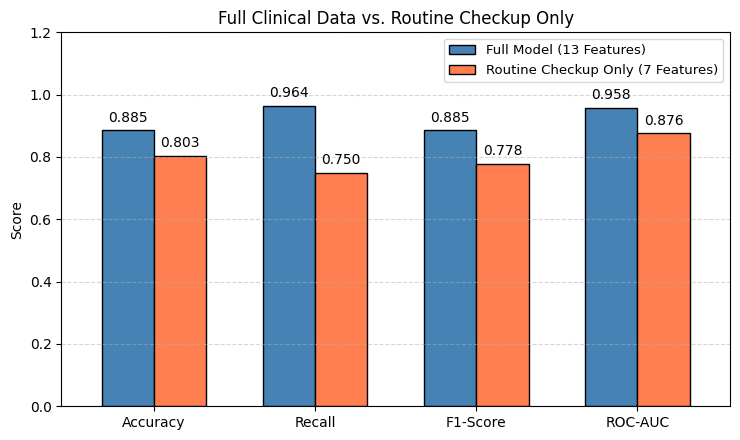

In [217]:
ablation_comparison = pd.DataFrame([
    {
        "Model": "Full Model (13 Features)",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": full_auc
    },
    {
        "Model": "Routine Checkup Only (7 Features)",
        "Accuracy": accuracy_score(y_test, y_pred_routine),
        "Recall": recall_score(y_test, y_pred_routine, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_routine, zero_division=0),
        "ROC-AUC": routine_auc
    },
])

ax = (
    ablation_comparison.set_index("Model")[["Accuracy", "Recall", "F1-Score", "ROC-AUC"]]
    .T.plot.bar(
        color=["steelblue", "coral"],
        edgecolor="black",
        width=0.65,
        figsize=(7.5, 4.5),
        rot=0,
        title="Full Clinical Data vs. Routine Checkup Only",
    )
)

for container in ax.containers:
  ax.bar_label(container, fmt="%.3f", padding=4, fontsize=10)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper right", fontsize=9.5)

plt.tight_layout()
plt.show()

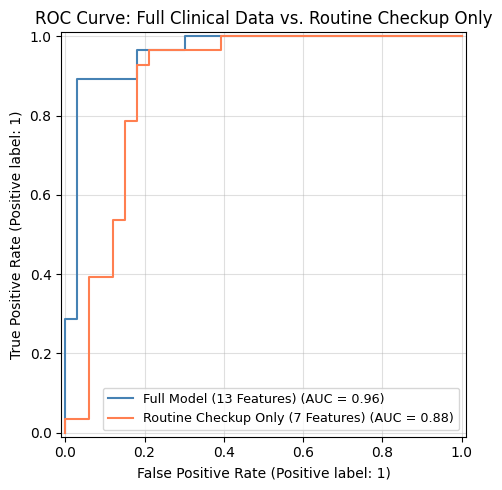

In [218]:
fig, ax = plt.subplots(figsize=(6.5, 5))

RocCurveDisplay.from_estimator(
    lr_model,
    X_test,
    y_test,
    name="Full Model (13 Features)",
    curve_kwargs={"color": "steelblue"},
    ax=ax,
)

RocCurveDisplay.from_estimator(
    routine_lr_model,
    X_test_routine,
    y_test,
    name="Routine Checkup Only (7 Features)",
    curve_kwargs={"color": "coral"},
    ax=ax,
)

ax.plot(
    linestyle="--",
    color="gray",
    label="Random Chance (AUC = 0.50)",
)
ax.set_title("ROC Curve: Full Clinical Data vs. Routine Checkup Only")
ax.grid(alpha=0.4)
ax.legend(loc="lower right", fontsize=9.2)

plt.tight_layout()
plt.show()

### 📊 Findings: Full Clinical Data vs. Routine Checkup Only

Removing specialized cardiac tests (`ca`, `thal`, `oldpeak`, `thalach`, `exang`, `slope`) revealed a clear trade-off between accessibility and diagnostic performance:

* **Overall Accuracy (`0.885` → `0.803`):** Dropped by **8.2 percentage points**. While routine checkup features—especially chest pain type (`cp`), age, and sex—retain solid predictive power, specialized tests meaningfully improve overall accuracy.
* **Recall (`0.964` → `0.750`):** Dropped by **21.4 percentage points**, meaning the routine-only model missed **6 additional positive heart disease cases** (catching `21/28` instead of `27/28`).
* **F1-Score (`0.885` → `0.778`):** Decreased by **0.107**, reflecting a noticeable decline in the balance between precision and sensitivity without specialized test measurements.
* **ROC-AUC (`0.958` → `0.876`):** Dropped by **0.082**, demonstrating that specialized tests substantially improve the model's ability to separate high-risk and low-risk patients across all classification thresholds.

> **💡 Clinical Takeaway:** Routine checkup data achieves **80.3% accuracy**, making it a practical, low-cost first-step screening tool in primary care clinics where specialized equipment is unavailable. However, specialized cardiac tests remain essential for maximizing recall (**96.4%**) and risk discrimination (**0.958 AUC**) so high-risk patients are not missed.


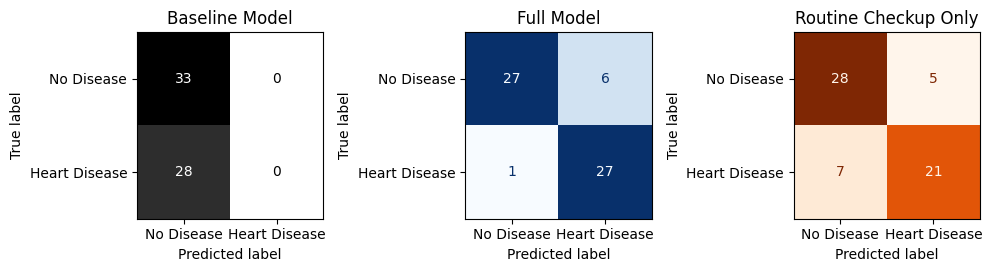

In [219]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(y_test, baseline_pred, display_labels=["No Disease", "Heart Disease"], cmap="Grays", colorbar=False, ax=ax1)
ax1.set_title("Baseline Model")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No Disease", "Heart Disease"], cmap="Blues", colorbar=False, ax=ax2)
ax2.set_title("Full Model")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_routine, display_labels=["No Disease", "Heart Disease"], cmap="Oranges", colorbar=False, ax=ax3)
ax3.set_title("Routine Checkup Only")

plt.tight_layout()
plt.show()

In [220]:
def error_analysis(y_true, y_pred, model_name):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results = pd.DataFrame([
        {
            "Model": model_name,
            "Error Type": "False Negatives (Missed Cases)",
            "Count": fn,
            "Meaning": "Actual heart disease, predicted no disease"
        },
        {
            "Model": model_name,
            "Error Type": "False Positives (False Alarms)",
            "Count": fp,
            "Meaning": "Actual no disease, predicted heart disease"
        }
    ])

    return results


baseline_errors = error_analysis(
    y_test, baseline_pred, "Baseline"
)

full_errors = error_analysis(
    y_test, y_pred, "Full Model"
)

routine_errors = error_analysis(
    y_test, y_pred_routine, "Routine Model"
)


error_comparison = pd.concat(
    [baseline_errors, full_errors, routine_errors],
    ignore_index=True
)

error_comparison

,Model,Error Type,Count,Meaning
0,Baseline,False Negatives (Missed Cases),28,"Actual heart disease, predicted no disease"
1,Baseline,False Positives (False Alarms),0,"Actual no disease, predicted heart disease"
2,Full Model,False Negatives (Missed Cases),1,"Actual heart disease, predicted no disease"
3,Full Model,False Positives (False Alarms),6,"Actual no disease, predicted heart disease"
4,Routine Model,False Negatives (Missed Cases),7,"Actual heart disease, predicted no disease"
5,Routine Model,False Positives (False Alarms),5,"Actual no disease, predicted heart disease"


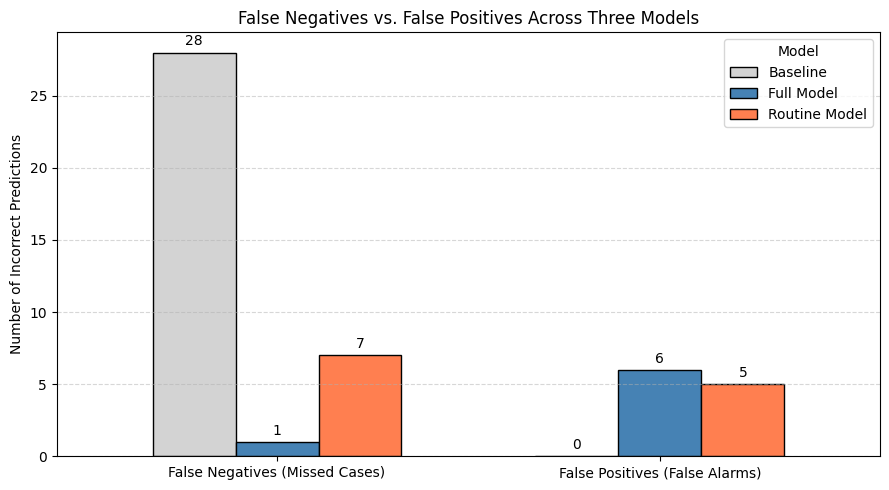

In [221]:
error_plot = error_comparison.pivot(
    index="Error Type",
    columns="Model",
    values="Count"
)

error_plot = error_plot[
    ["Baseline", "Full Model", "Routine Model"]
]

ax = error_plot.plot.bar(
    figsize=(9, 5),
    color=["lightgray", "steelblue", "coral"],
    edgecolor="black",
    width=0.65,
    rot=0,
    title="False Negatives vs. False Positives Across Three Models"
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

ax.set_ylabel("Number of Incorrect Predictions")
ax.set_xlabel("")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Model")

plt.tight_layout()
plt.show()

In [222]:
background = shap.sample(X_train, 100, random_state=42)

In [223]:
joblib.dump(background, "shap_background.joblib");

In [224]:
joblib.dump(lr_model, "lr_model.joblib");

In [225]:
joblib.dump(baseline, "baseline_model.joblib");

In [226]:
joblib.dump(routine_lr_model, "routine_lr_model.joblib");